=== อัตราการพบโรคทางจิต (%) เรียงจากสูงไปต่ำ ===


,mean,median,std,min,max,rank
disease,,,,,,
Anxiety,4.106,3.941,1.079,1.880,8.625,1
Depressive,3.785,3.682,0.949,1.522,7.646,2
Bipolar,0.649,0.582,0.233,0.182,1.507,3
Schizophrenia,0.265,0.272,0.040,0.188,0.462,4
Eating,0.198,0.148,0.140,0.045,1.032,5



คำตอบ: โรคที่มีอัตราการพบสูงสุดโดยเฉลี่ยคือ Anxiety (เฉลี่ย 4.106%)

โรคที่เฉลี่ยสูงสุดในแต่ละปี (จำนวนปี):
Anxiety    30
Name: count, dtype: int64


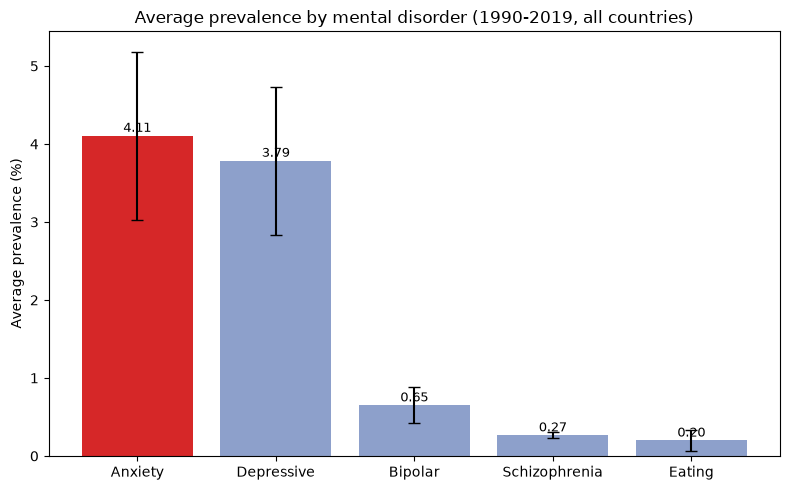


บันทึกแล้วใน Results/tables และ Results/figures


In [1]:
#คำถามที่ 1 โรคทางจิตประเภทใดมีอัตราการพบสูงสุดโดยเฉลี่ย
import os
import pandas as pd
import matplotlib.pyplot as plt

BASE = r"C:\Users\LENOVO\OneDrive - BUU\Desktop\Data"
df = pd.read_csv(os.path.join(BASE, "processed", "mental_income_merged.csv"))

diseases = ["Schizophrenia", "Depressive", "Anxiety", "Bipolar", "Eating"]

# ---------- 1) ค่าเฉลี่ยรวมทุกประเทศ-ทุกปี ----------
summary = (df[diseases]
           .agg(["mean", "median", "std", "min", "max"])
           .T.round(3)
           .sort_values("mean", ascending=False))
summary.index.name = "disease"
summary["rank"] = range(1, len(summary) + 1)

print("=== อัตราการพบโรคทางจิต (%) เรียงจากสูงไปต่ำ ===")
display(summary)

top = summary.index[0]
print(f"\nคำตอบ: โรคที่มีอัตราการพบสูงสุดโดยเฉลี่ยคือ {top} "
      f"(เฉลี่ย {summary.loc[top, 'mean']:.3f}%)")

# ---------- 2) เช็กความคงเส้นคงวา: เป็นอันดับ 1 ทุกปีไหม ----------
yearly = df.groupby("year")[diseases].mean()
top_each_year = yearly.idxmax(axis=1).value_counts()
print("\nโรคที่เฉลี่ยสูงสุดในแต่ละปี (จำนวนปี):")
print(top_each_year)

# ---------- 3) กราฟแท่ง ----------
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(summary.index, summary["mean"],
              yerr=summary["std"], capsize=4,
              color=["#d62728" if d == top else "#8da0cb" for d in summary.index])
for b, v in zip(bars, summary["mean"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.05, f"{v:.2f}", ha="center", fontsize=9)
ax.set_ylabel("Average prevalence (%)")
ax.set_title("Average prevalence by mental disorder (1990-2019, all countries)")
plt.tight_layout()

# ---------- 4) บันทึก ----------
tab_dir = os.path.join(BASE, "..", "Results", "tables")
fig_dir = os.path.join(BASE, "..", "Results", "figures")
os.makedirs(tab_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

summary.to_csv(os.path.join(tab_dir, "disease_average_ranking.csv"), encoding="utf-8-sig")
fig.savefig(os.path.join(fig_dir, "disease_average_ranking.png"), dpi=300)
plt.show()
print("\nบันทึกแล้วใน Results/tables และ Results/figures")

In [ ]:
#Anxiety (โรควิตกกังวล) มีอัตราการพบสูงสุดโดยเฉลี่ยและAnxiety เป็นอันดับ 1 ทั้ง 30 ปี (ทุกปีใน 1990-2019) แปลว่าผลคงเส้นคงวา ไม่ได้เกิดจากปีใดปีหนึ่งโดยเฉพาะ
#Anxiety และ Depressive อยู่ในระดับสูงใกล้กัน (ต่างกันประมาณ 0.3 จุดเปอร์เซ็นต์) และสูงกว่าโรคอื่นประมาณ 6-20 เท่า
#แท่ง error bar คือส่วนเบี่ยงเบนมาตรฐาน (SD) ระหว่างประเทศ-ปี ไม่ใช่ช่วงความเชื่อมั่น ของ Anxiety และ Depressive ซ้อนทับกันมาก เพราะแต่ละประเทศมีค่าต่างกันเยอะ ควรเขียนใต้กราฟว่า "แถบความคลาดเคลื่อนแสดงค่า SD"
#ค่าเฉลี่ยให้น้ำหนักทุกประเทศเท่ากัน ไม่ถ่วงน้ำหนักด้วยประชากร

=== ประเทศอันดับ 1 ของแต่ละโรค ===


,disease,country,mean_prevalence
0,Schizophrenia,United States,0.449
10,Depressive,Uganda,7.143
20,Anxiety,Portugal,7.909
30,Bipolar,New Zealand,1.497
40,Eating,Australia,0.890
50,total_mental,Portugal,14.251



=== Top 10 รวมทุกโรค (total_mental) ===


,disease,rank,country,mean_prevalence
50,total_mental,1,Portugal,14.251
51,total_mental,2,New Zealand,13.473
52,total_mental,3,Palestine,13.387
53,total_mental,4,Iran,13.171
54,total_mental,5,Brazil,13.145
55,total_mental,6,Greenland,12.541
56,total_mental,7,Greece,12.514
57,total_mental,8,Australia,12.488
58,total_mental,9,Lebanon,12.428
59,total_mental,10,Ireland,12.242


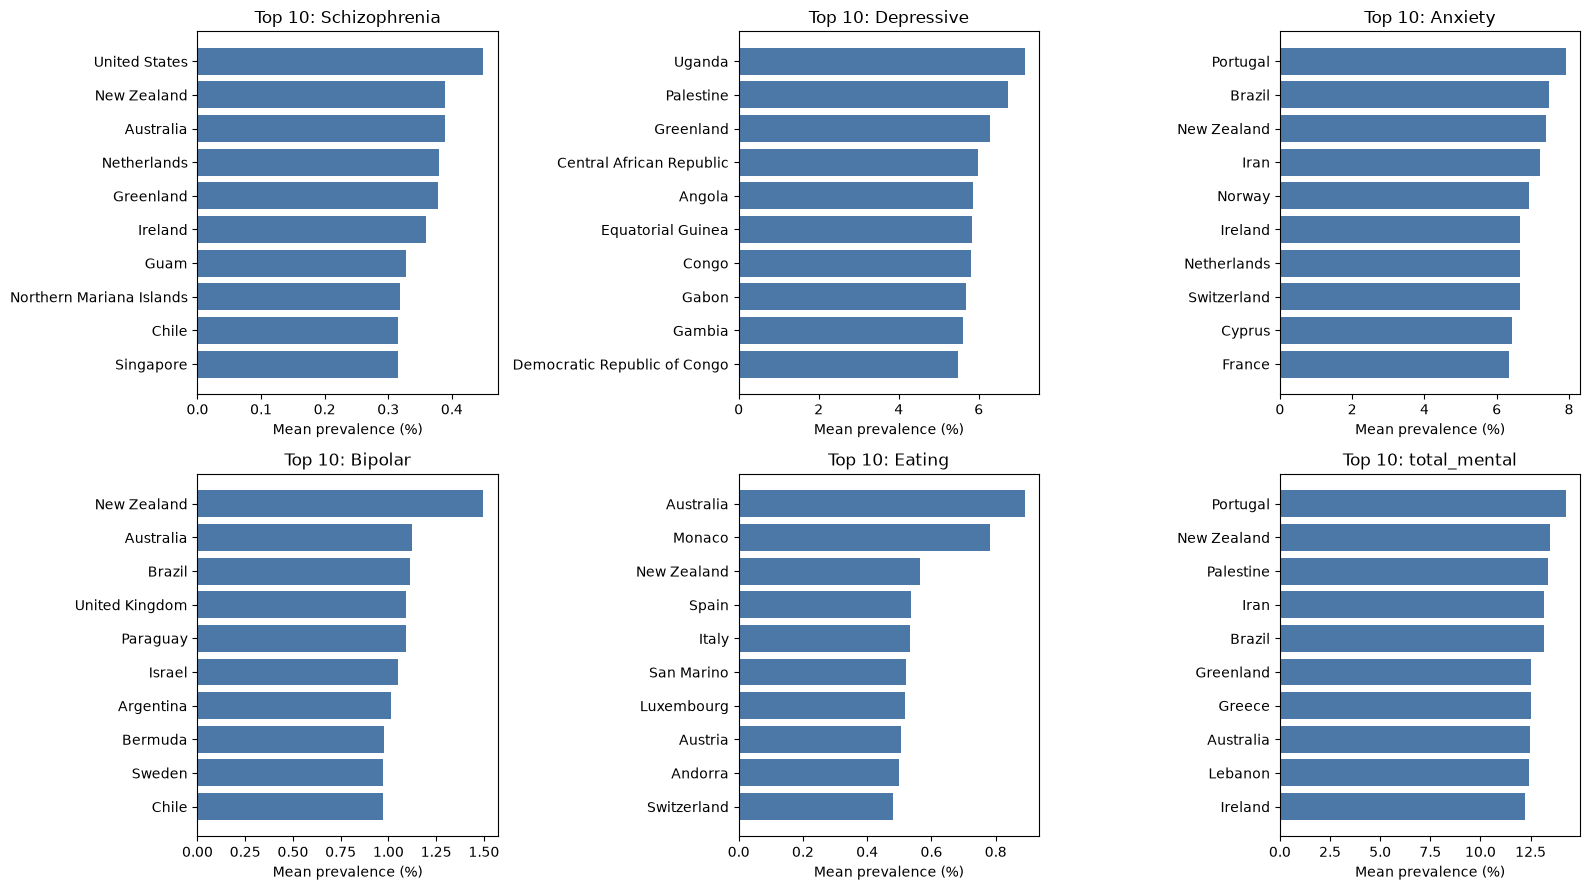


=== ค่าเฉลี่ยรายกลุ่มรายได้ ===


,Schizophrenia,Depressive,Anxiety,Bipolar,Eating,total_mental
income_group,,,,,,
Low income,0.227,4.337,3.481,0.535,0.089,8.670
Lower-middle income,0.261,3.683,3.956,0.586,0.134,8.619
Upper-middle income,0.278,3.492,4.188,0.682,0.191,8.831
High income,0.297,3.595,4.826,0.805,0.384,9.907



=== Spearman + Kruskal-Wallis ===


,disease,spearman_rho,spearman_p,kruskal_H,kruskal_p,epsilon_sq,rho_2019_only,p_2019_only
0,Schizophrenia,0.6566,0.0,2595.8195,0.0,0.4424,0.7133,0.0000
1,Depressive,-0.2772,0.0,723.1986,0.0,0.1233,-0.3599,0.0000
2,Anxiety,0.4502,0.0,1214.7678,0.0,0.2071,0.3452,0.0000
3,Bipolar,0.4318,0.0,1155.8402,0.0,0.1970,0.3644,0.0000
4,Eating,0.8424,0.0,4179.1640,0.0,0.7123,0.7956,0.0000
5,total_mental,0.2403,0.0,550.5867,0.0,0.0938,0.1285,0.0691


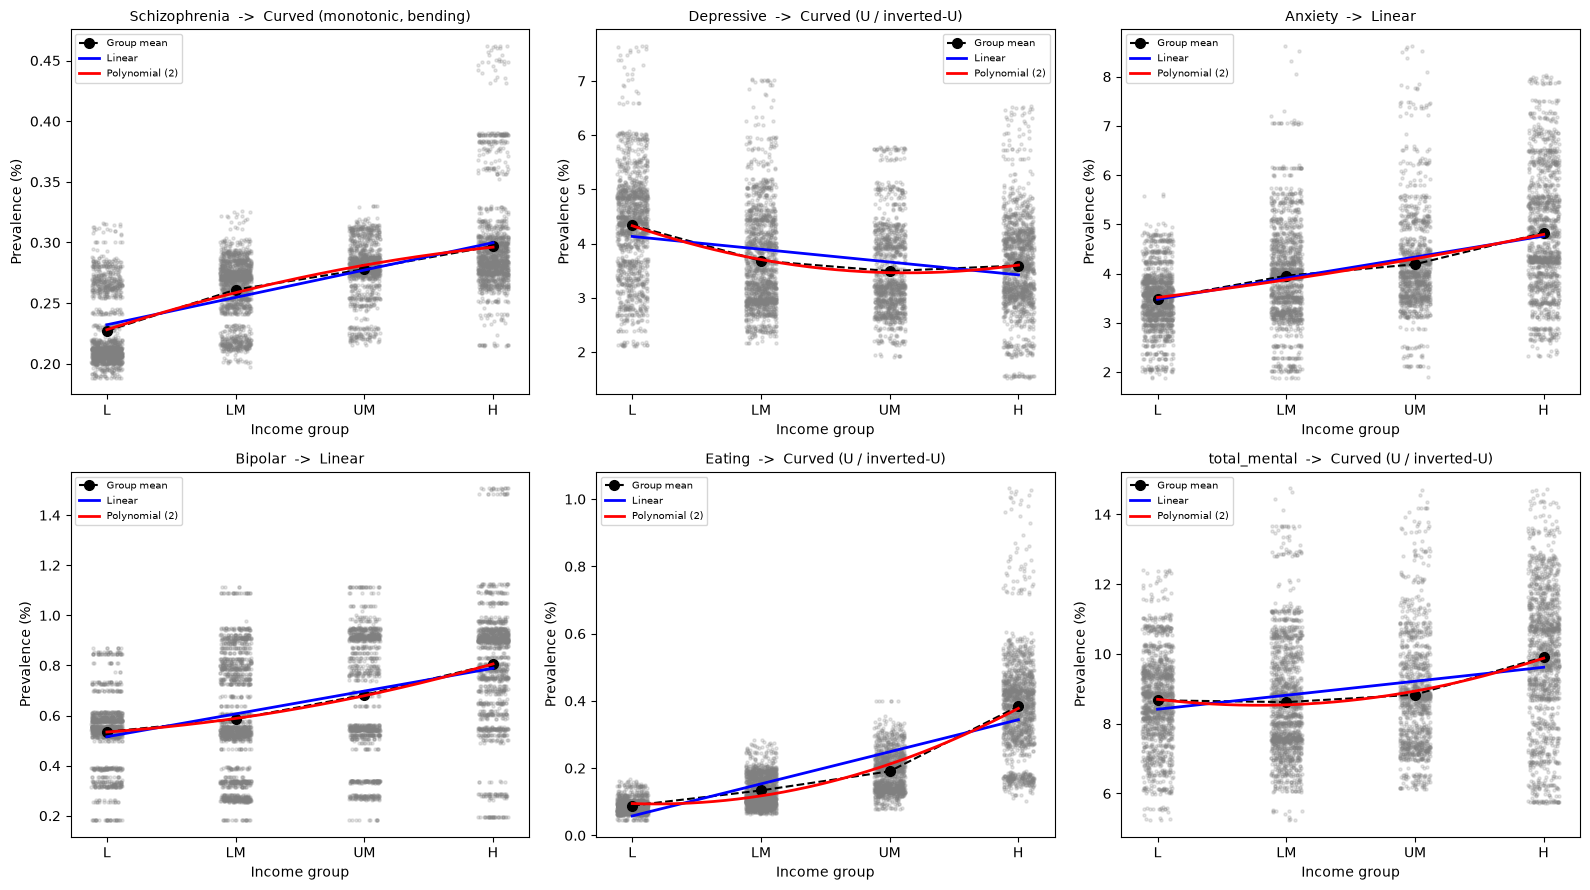


=== Linear vs Polynomial ===


,disease,R2_linear,R2_poly,adjR2_linear,adjR2_poly,AIC_linear,AIC_poly,slope_linear,quad_coef,p_quad_cluster,p_Ftest,turning_point_code,conclusion
0,Schizophrenia,0.4054,0.4151,0.4053,0.4149,-24243.5007,-24337.1892,0.0226,-0.0039,0.0330,0.0000,5.4070,"Curved (monotonic, bending)"
1,Depressive,0.0781,0.1186,0.0780,0.1183,15564.1879,15302.4664,-0.2364,0.1911,0.0003,0.0000,3.1333,Curved (U / inverted-U)
2,Anxiety,0.1986,0.1996,0.1985,0.1993,16247.5348,16242.1361,0.4285,0.0343,0.5491,0.0065,-3.7323,Linear
3,Bipolar,0.1930,0.1991,0.1929,0.1989,-1711.2554,-1753.7792,0.0911,0.0182,0.1441,0.0000,0.0088,Linear
4,Eating,0.5826,0.6475,0.5825,0.6473,-11524.1370,-12512.8173,0.0954,0.0357,0.0000,0.0000,1.1794,Curved (U / inverted-U)
5,total_mental,0.0694,0.0954,0.0693,0.0951,22520.4335,22356.4111,0.4012,0.2754,0.0040,0.0000,1.7863,Curved (U / inverted-U)



บันทึกตารางใน Results/tables และกราฟใน Results/figures แล้ว


In [5]:
#คำถามที่ 2 ประเทศใดมีอัตราผู้ป่วยโรคทางจิตสูงที่สุดและประเภทของโรคทางจิตมีความสัมพันธ์กับรายได้ของประเทศหรือไม่ แล้วสัมพันธ์แบบแส้นตรงหรือเส้นโค้ง
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

BASE = r"C:\Users\LENOVO\OneDrive - BUU\Desktop\Data"
df = pd.read_csv(os.path.join(BASE, "processed", "mental_income_merged.csv"))

diseases = ["Schizophrenia", "Depressive", "Anxiety", "Bipolar", "Eating"]
df["total_mental"] = df[diseases].sum(axis=1)      # ผลรวมทุกโรค (ดัชนีภาระโรครวม)
targets = diseases + ["total_mental"]

tab_dir = os.path.join(BASE, "..", "Results", "tables")
fig_dir = os.path.join(BASE, "..", "Results", "figures")
os.makedirs(tab_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)


# =====================================================
# ฟังก์ชัน OLS แทน statsmodels
# =====================================================
def ols_fit(X, y, groups=None):
    n, k = X.shape
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    resid = y - X @ beta
    rss = resid @ resid
    tss = ((y - y.mean()) ** 2).sum()
    r2 = 1 - rss / tss
    adj = 1 - (1 - r2) * (n - 1) / (n - k)
    aic = n * np.log(rss / n) + 2 * (k + 1) + n * (1 + np.log(2 * np.pi))

    sigma2 = rss / (n - k)
    se = np.sqrt(np.diag(sigma2 * XtX_inv))
    p = 2 * stats.t.sf(np.abs(beta / se), n - k)

    p_cl = None
    if groups is not None:                      # cluster-robust ตามประเทศ
        G = np.unique(groups)
        meat = np.zeros((k, k))
        for g in G:
            s = X[groups == g].T @ resid[groups == g]
            meat += np.outer(s, s)
        c = len(G) / (len(G) - 1) * (n - 1) / (n - k)
        V = c * XtX_inv @ meat @ XtX_inv
        p_cl = 2 * stats.t.sf(np.abs(beta / np.sqrt(np.diag(V))), len(G) - 1)

    return dict(params=beta, r2=r2, adj=adj, aic=aic, rss=rss, k=k, n=n, p=p, p_cl=p_cl)


# =====================================================
# ส่วนที่ 1: ประเทศใดมีอัตราสูงที่สุด (ค่าเฉลี่ย 1990-2019)
# =====================================================
avg = (df.groupby(["country_code", "country_name_mental"])[targets]
         .mean().reset_index())

rows = []
for col in targets:
    t = avg.nlargest(10, col)[["country_name_mental", col]].reset_index(drop=True)
    t.insert(0, "rank", range(1, 11))
    t.insert(0, "disease", col)
    t.columns = ["disease", "rank", "country", "mean_prevalence"]
    rows.append(t)
top10_all = pd.concat(rows, ignore_index=True)

print("=== ประเทศอันดับ 1 ของแต่ละโรค ===")
display(top10_all[top10_all["rank"] == 1][["disease", "country", "mean_prevalence"]].round(3))
print("\n=== Top 10 รวมทุกโรค (total_mental) ===")
display(top10_all[top10_all["disease"] == "total_mental"].round(3))

top10_all.to_csv(os.path.join(tab_dir, "top10_countries_by_disease.csv"),
                 index=False, encoding="utf-8-sig")

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.ravel(), targets):
    t = top10_all[top10_all["disease"] == col].iloc[::-1]
    ax.barh(t["country"], t["mean_prevalence"], color="#4c78a8")
    ax.set_title(f"Top 10: {col}")
    ax.set_xlabel("Mean prevalence (%)")
plt.tight_layout()
fig.savefig(os.path.join(fig_dir, "top10_countries.png"), dpi=300)
plt.show()


# =====================================================
# ส่วนที่ 2: โรคแต่ละประเภทสัมพันธ์กับรายได้ไหม
# =====================================================
order = ["Low income", "Lower-middle income", "Upper-middle income", "High income"]
code = {g: i + 1 for i, g in enumerate(order)}
df["income_code"] = df["income_group"].map(code)

print("\n=== ค่าเฉลี่ยรายกลุ่มรายได้ ===")
group_mean = df.groupby("income_group")[targets].mean().loc[order].round(3)
display(group_mean)
group_mean.to_csv(os.path.join(tab_dir, "mean_by_income_group.csv"), encoding="utf-8-sig")

assoc = []
d19 = df[df["year"] == 2019]
for col in targets:
    x, y = df["income_code"].values, df[col].values
    rho, p_rho = stats.spearmanr(x, y)
    H, p_kw = stats.kruskal(*[y[x == k] for k in (1, 2, 3, 4)])
    eps2 = H / (len(y) - 1)                         # ขนาดอิทธิพล (epsilon squared)
    rho19, p19 = stats.spearmanr(d19["income_code"], d19[col])
    assoc.append({"disease": col, "spearman_rho": rho, "spearman_p": p_rho,
                  "kruskal_H": H, "kruskal_p": p_kw, "epsilon_sq": eps2,
                  "rho_2019_only": rho19, "p_2019_only": p19})
assoc = pd.DataFrame(assoc)
print("\n=== Spearman + Kruskal-Wallis ===")
display(assoc.round(4))
assoc.to_csv(os.path.join(tab_dir, "income_association_tests.csv"),
             index=False, encoding="utf-8-sig")


# =====================================================
# ส่วนที่ 3: เส้นตรงหรือเส้นโค้ง (Linear vs Polynomial ดีกรี 2)
# =====================================================
xs = np.linspace(1, 4, 200)
res = []
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
rng = np.random.default_rng(42)
grp = pd.factorize(df["country_code"])[0]

for ax, col in zip(axes.ravel(), targets):
    x = df["income_code"].values.astype(float)
    y = df[col].values
    X1 = np.column_stack([np.ones_like(x), x])
    X2 = np.column_stack([np.ones_like(x), x, x ** 2])

    m1 = ols_fit(X1, y)
    m2 = ols_fit(X2, y, groups=grp)

    # F-test: เพิ่มพจน์กำลังสองแล้วดีขึ้นไหม
    F = (m1["rss"] - m2["rss"]) / (m2["rss"] / (m2["n"] - m2["k"]))
    p_f = stats.f.sf(F, 1, m2["n"] - m2["k"])

    b0, b1, b2 = m2["params"]
    vertex = -b1 / (2 * b2) if b2 != 0 else np.nan
    curved = (m2["p_cl"][2] < 0.05) and (m2["aic"] < m1["aic"])
    if not curved:
        shape = "Linear"
    elif 1 < vertex < 4:
        shape = "Curved (U / inverted-U)"
    else:
        shape = "Curved (monotonic, bending)"

    res.append({"disease": col,
                "R2_linear": m1["r2"], "R2_poly": m2["r2"],
                "adjR2_linear": m1["adj"], "adjR2_poly": m2["adj"],
                "AIC_linear": m1["aic"], "AIC_poly": m2["aic"],
                "slope_linear": m1["params"][1], "quad_coef": b2,
                "p_quad_cluster": m2["p_cl"][2], "p_Ftest": p_f,
                "turning_point_code": vertex, "conclusion": shape})

    ax.scatter(x + rng.uniform(-0.12, 0.12, len(x)), y, s=5, alpha=0.2, color="gray")
    gm = df.groupby("income_code")[col].mean()
    ax.plot(gm.index, gm.values, "ko--", ms=7, label="Group mean")
    ax.plot(xs, m1["params"][0] + m1["params"][1] * xs, "b-", lw=2, label="Linear")
    ax.plot(xs, b0 + b1 * xs + b2 * xs ** 2, "r-", lw=2, label="Polynomial (2)")
    ax.set_xticks([1, 2, 3, 4])
    ax.set_xticklabels(["L", "LM", "UM", "H"])
    ax.set_title(f"{col}  ->  {shape}", fontsize=10)
    ax.set_xlabel("Income group")
    ax.set_ylabel("Prevalence (%)")
    ax.legend(fontsize=7)

plt.tight_layout()
fig.savefig(os.path.join(fig_dir, "linear_vs_polynomial.png"), dpi=300)
plt.show()

res = pd.DataFrame(res)
print("\n=== Linear vs Polynomial ===")
display(res.round(4))
res.to_csv(os.path.join(tab_dir, "linear_vs_polynomial.csv"),
           index=False, encoding="utf-8-sig")

print("\nบันทึกตารางใน Results/tables และกราฟใน Results/figures แล้ว")

In [ ]:
#ประเทศที่มีอัตราโรคทางจิตรวมสูงสุดคือ Portugal (14.25%) ตามด้วย New Zealand และ Palestine ทั้งนี้ขึ้นกับชนิดโรค ประเภทของโรคทางจิตมีความสัมพันธ์กับระดับรายได้ของประเทศทุกโรค 
# โดย Eating disorders (ρ = 0.84), Schizophrenia (ρ = 0.66), Anxiety และ Bipolar มีความสัมพันธ์ทางบวก ขณะที่ Depressive มีความสัมพันธ์ทางลบ (ρ = −0.28) 
# ในด้านรูปแบบ Anxiety และ Bipolar เป็นเส้นตรง Depressive เป็นเส้นโค้งรูปตัว U (ลดลงแล้วเพิ่มขึ้นเล็กน้อยในกลุ่มรายได้สูง) และ Eating เป็นเส้นโค้งที่เพิ่มขึ้นแบบเร่งในกลุ่มรายได้สูง

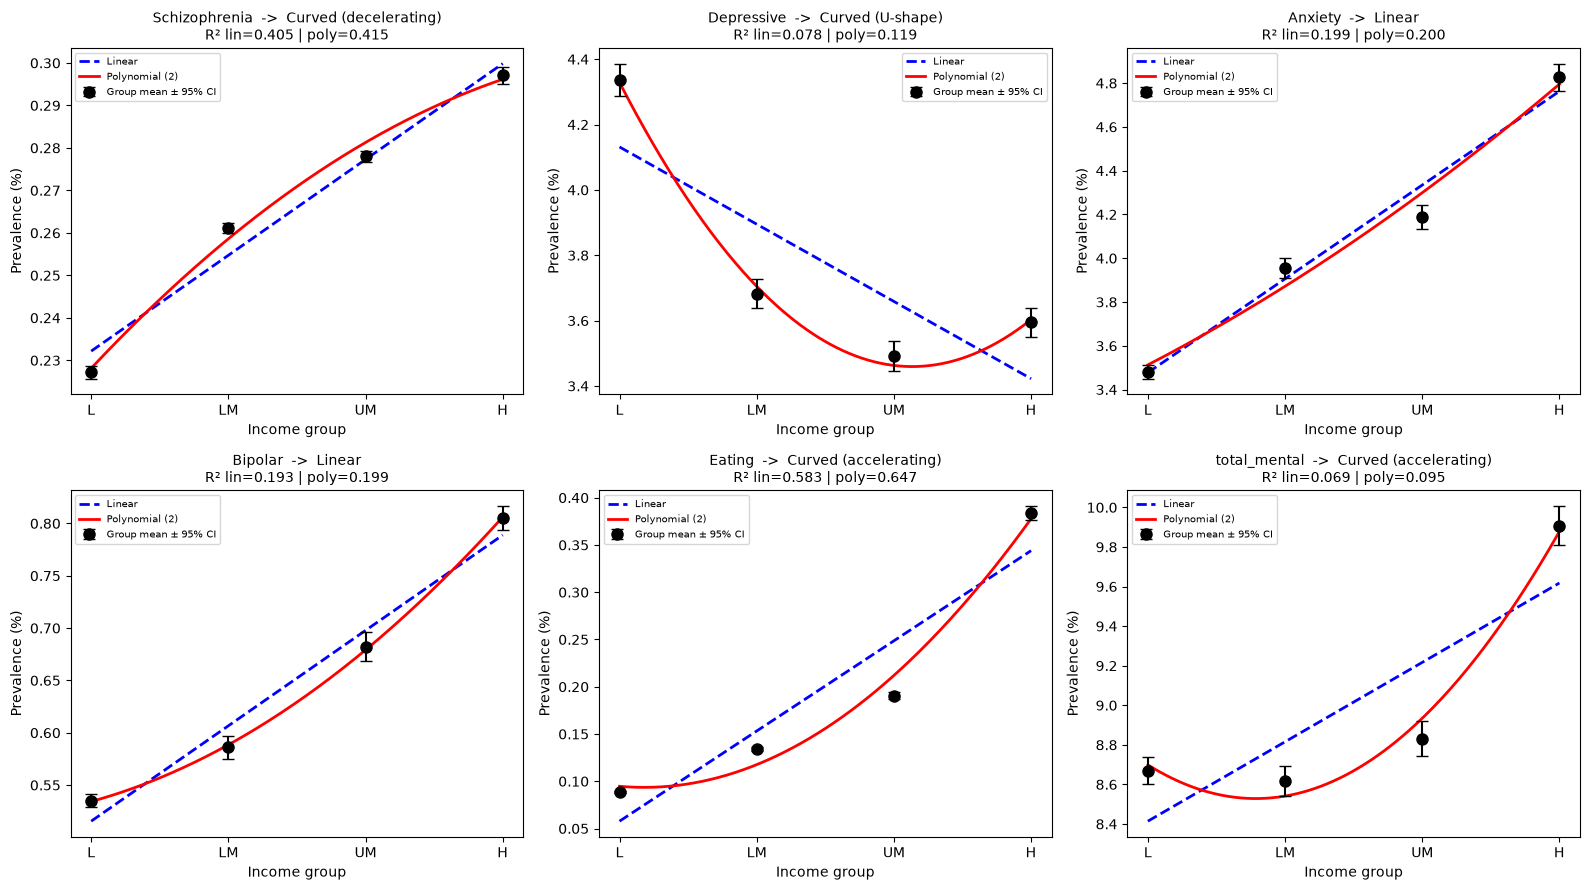

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
xs = np.linspace(1, 4, 200)

for ax, col in zip(axes.ravel(), targets):
    r = res[res["disease"] == col].iloc[0]
    x = df["income_code"].values.astype(float)
    y = df[col].values

    # ค่าเฉลี่ยรายกลุ่ม + CI 95%
    g = df.groupby("income_code")[col]
    m, se = g.mean(), g.sem()
    ax.errorbar(m.index, m.values, yerr=1.96 * se.values, fmt="ko", ms=8,
                capsize=4, label="Group mean ± 95% CI", zorder=3)

    # เส้นตรง และเส้นโค้ง
    X1 = np.column_stack([np.ones_like(x), x])
    X2 = np.column_stack([np.ones_like(x), x, x ** 2])
    b_lin = ols_fit(X1, y)["params"]
    b_poly = ols_fit(X2, y)["params"]
    ax.plot(xs, b_lin[0] + b_lin[1] * xs, "b--", lw=2, label="Linear")
    ax.plot(xs, b_poly[0] + b_poly[1] * xs + b_poly[2] * xs ** 2, "r-", lw=2,
            label="Polynomial (2)")

    # ป้ายกำกับตามรูปร่างจริง
    if r["p_quad_cluster"] >= 0.05 or r["AIC_poly"] >= r["AIC_linear"]:
        shape = "Linear"
    elif col == "Depressive":
        shape = "Curved (U-shape)"
    elif r["quad_coef"] > 0:
        shape = "Curved (accelerating)"
    else:
        shape = "Curved (decelerating)"

    ax.set_title(f"{col}  ->  {shape}\n"
                 f"R² lin={r['R2_linear']:.3f} | poly={r['R2_poly']:.3f}", fontsize=10)
    ax.set_xticks([1, 2, 3, 4])
    ax.set_xticklabels(["L", "LM", "UM", "H"])
    ax.set_xlabel("Income group")
    ax.set_ylabel("Prevalence (%)")
    ax.legend(fontsize=7)

plt.tight_layout()
fig.savefig(os.path.join(fig_dir, "linear_vs_polynomial_means.png"), dpi=300)
plt.show()

In [7]:
#สมการของทุกโรค
eq_rows = []
for col in targets:
    x = df["income_code"].values.astype(float)
    y = df[col].values
    b_lin = ols_fit(np.column_stack([np.ones_like(x), x]), y)["params"]
    b_poly = ols_fit(np.column_stack([np.ones_like(x), x, x ** 2]), y)["params"]
    r = res[res["disease"] == col].iloc[0]
    eq_rows.append({
        "disease": col,
        "linear_equation": f"y = {b_lin[0]:.4f} + {b_lin[1]:.4f}x",
        "poly_equation": f"y = {b_poly[0]:.4f} + {b_poly[1]:.4f}x + {b_poly[2]:.4f}x²",
        "R2_linear": round(r["R2_linear"], 3),
        "R2_poly": round(r["R2_poly"], 3),
        "conclusion": r["conclusion"],
    })
eq = pd.DataFrame(eq_rows)
pd.set_option("display.max_colwidth", None)
display(eq)
eq.to_csv(os.path.join(tab_dir, "regression_equations.csv"), index=False, encoding="utf-8-sig")

,disease,linear_equation,poly_equation,R2_linear,R2_poly,conclusion
0,Schizophrenia,y = 0.2096 + 0.0226x,y = 0.1899 + 0.0422x + -0.0039x²,0.405,0.415,"Curved (monotonic, bending)"
1,Depressive,y = 4.3679 + -0.2364x,y = 5.3354 + -1.1974x + 0.1911x²,0.078,0.119,Curved (U / inverted-U)
2,Anxiety,y = 3.0489 + 0.4285x,y = 3.2225 + 0.2560x + 0.0343x²,0.199,0.200,Linear
3,Bipolar,y = 0.4244 + 0.0911x,y = 0.5164 + -0.0003x + 0.0182x²,0.193,0.199,Linear
4,Eating,y = -0.0376 + 0.0954x,y = 0.1432 + -0.0843x + 0.0357x²,0.583,0.647,Curved (U / inverted-U)
5,total_mental,y = 8.0131 + 0.4012x,y = 9.4074 + -0.9838x + 0.2754x²,0.069,0.095,Curved (U / inverted-U)


In [8]:
def shape_label(row):
    # เส้นตรงชนะ ถ้าพจน์กำลังสองไม่มีนัยสำคัญ หรือ AIC ไม่ดีขึ้น
    if row["p_quad_cluster"] >= 0.05 or row["AIC_poly"] >= row["AIC_linear"]:
        return "Linear"
    # Schizophrenia: โค้งน้อยมาก (R² เพิ่มไม่ถึง 0.02) ถือว่าเกือบเป็นเส้นตรง
    if (row["R2_poly"] - row["R2_linear"]) < 0.02:
        return "Nearly linear (slight curve)"
    # Depressive: ลดลงแล้วกลับขึ้นในช่วงข้อมูล (จุดเปลี่ยนอยู่ระหว่าง 1-4 และสัมประสิทธิ์ x ติดลบ)
    if 1 < row["turning_point_code"] < 4 and row["slope_linear"] < 0:
        return "U-shape"
    # ที่เหลือ: สัมประสิทธิ์กำลังสองบวก = เร่งขึ้น, ลบ = ชะลอลง
    return "Accelerating" if row["quad_coef"] > 0 else "Decelerating"

res["conclusion"] = res.apply(shape_label, axis=1)

# อัปเดตตารางสมการด้วย
eq["conclusion"] = eq["disease"].map(res.set_index("disease")["conclusion"])

display(res[["disease", "R2_linear", "R2_poly", "p_quad_cluster", "conclusion"]].round(4))
display(eq)

res.to_csv(os.path.join(tab_dir, "linear_vs_polynomial.csv"), index=False, encoding="utf-8-sig")
eq.to_csv(os.path.join(tab_dir, "regression_equations.csv"), index=False, encoding="utf-8-sig")
print("บันทึกใหม่แล้ว")

,disease,R2_linear,R2_poly,p_quad_cluster,conclusion
0,Schizophrenia,0.4054,0.4151,0.0330,Nearly linear (slight curve)
1,Depressive,0.0781,0.1186,0.0003,U-shape
2,Anxiety,0.1986,0.1996,0.5491,Linear
3,Bipolar,0.1930,0.1991,0.1441,Linear
4,Eating,0.5826,0.6475,0.0000,Accelerating
5,total_mental,0.0694,0.0954,0.0040,Accelerating


,disease,linear_equation,poly_equation,R2_linear,R2_poly,conclusion
0,Schizophrenia,y = 0.2096 + 0.0226x,y = 0.1899 + 0.0422x + -0.0039x²,0.405,0.415,Nearly linear (slight curve)
1,Depressive,y = 4.3679 + -0.2364x,y = 5.3354 + -1.1974x + 0.1911x²,0.078,0.119,U-shape
2,Anxiety,y = 3.0489 + 0.4285x,y = 3.2225 + 0.2560x + 0.0343x²,0.199,0.200,Linear
3,Bipolar,y = 0.4244 + 0.0911x,y = 0.5164 + -0.0003x + 0.0182x²,0.193,0.199,Linear
4,Eating,y = -0.0376 + 0.0954x,y = 0.1432 + -0.0843x + 0.0357x²,0.583,0.647,Accelerating
5,total_mental,y = 8.0131 + 0.4012x,y = 9.4074 + -0.9838x + 0.2754x²,0.069,0.095,Accelerating


บันทึกใหม่แล้ว


=== สัดส่วนรวม (1990-2019) ===


,share_%,mean_prevalence_%
Anxiety,45.61,4.106
Depressive,42.04,3.785
Bipolar,7.21,0.649
Schizophrenia,2.95,0.265
Eating,2.20,0.198



=== สัดส่วนแยกตามกลุ่มรายได้ (%) ===


,Schizophrenia,Depressive,Anxiety,Bipolar,Eating
income_group,,,,,
Low income,2.62,50.03,40.16,6.17,1.02
Lower-middle income,3.03,42.73,45.89,6.80,1.55
Upper-middle income,3.15,39.54,47.42,7.73,2.16
High income,3.00,36.28,48.72,8.13,3.87



=== สัดส่วนปี 1990 vs 2019 (จุดเปอร์เซ็นต์) ===


,share_1990,share_2019,change_pp
Schizophrenia,2.849,2.967,0.118
Depressive,42.287,41.298,-0.989
Anxiety,45.483,46.184,0.701
Bipolar,7.306,7.165,-0.141
Eating,2.074,2.385,0.311



Wilcoxon Anxiety vs Depressive: p = 2.85e-56


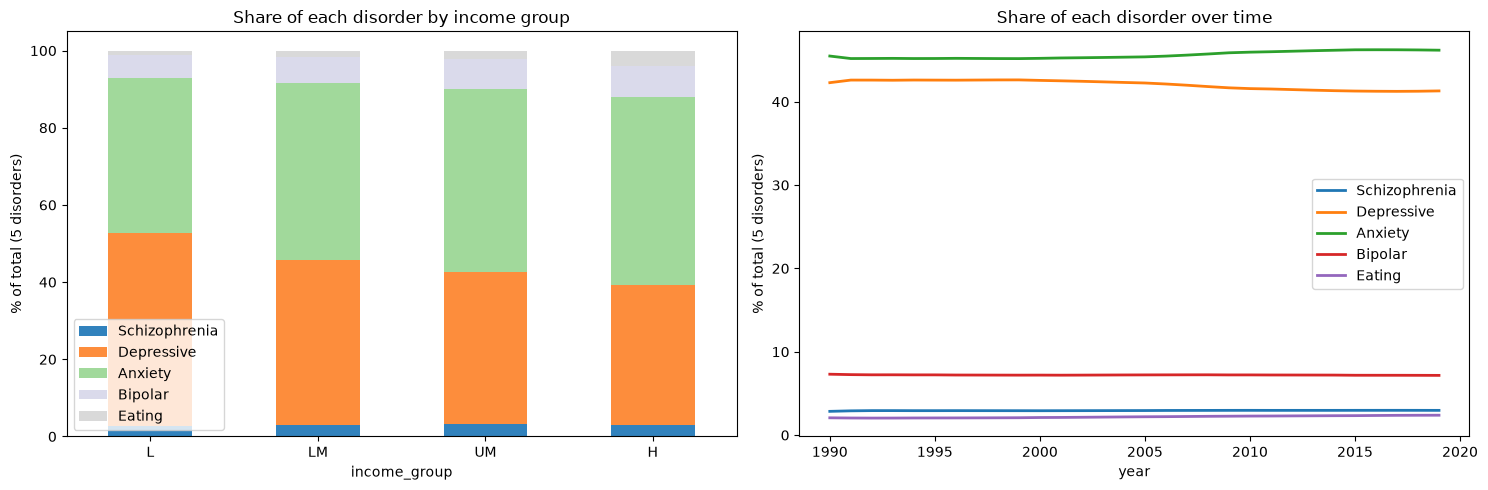


ประเทศที่ข้อมูลครบ 30 ปี: 166 จาก 201

=== Backtest (test = 2013-2019) ===


model,Linear,Naive,Poly2,RandomForest
disease,,,,
Anxiety,0.03125,0.02376,0.01785,0.02745
Bipolar,0.00095,0.00002,0.00120,0.00002
Depressive,0.01641,0.00601,0.07876,0.00810
Eating,0.00118,0.00566,0.00530,0.00622
Schizophrenia,0.00023,0.00049,0.00068,0.00056


โมเดลที่ดีที่สุดของแต่ละโรค:


,model,RMSE,MAPE_%
disease,,,
Anxiety,Poly2,0.0178,0.3045
Bipolar,RandomForest,0.0000,0.0018
Depressive,Naive,0.0060,0.1524
Eating,Linear,0.0012,0.5161
Schizophrenia,Linear,0.0002,0.0819


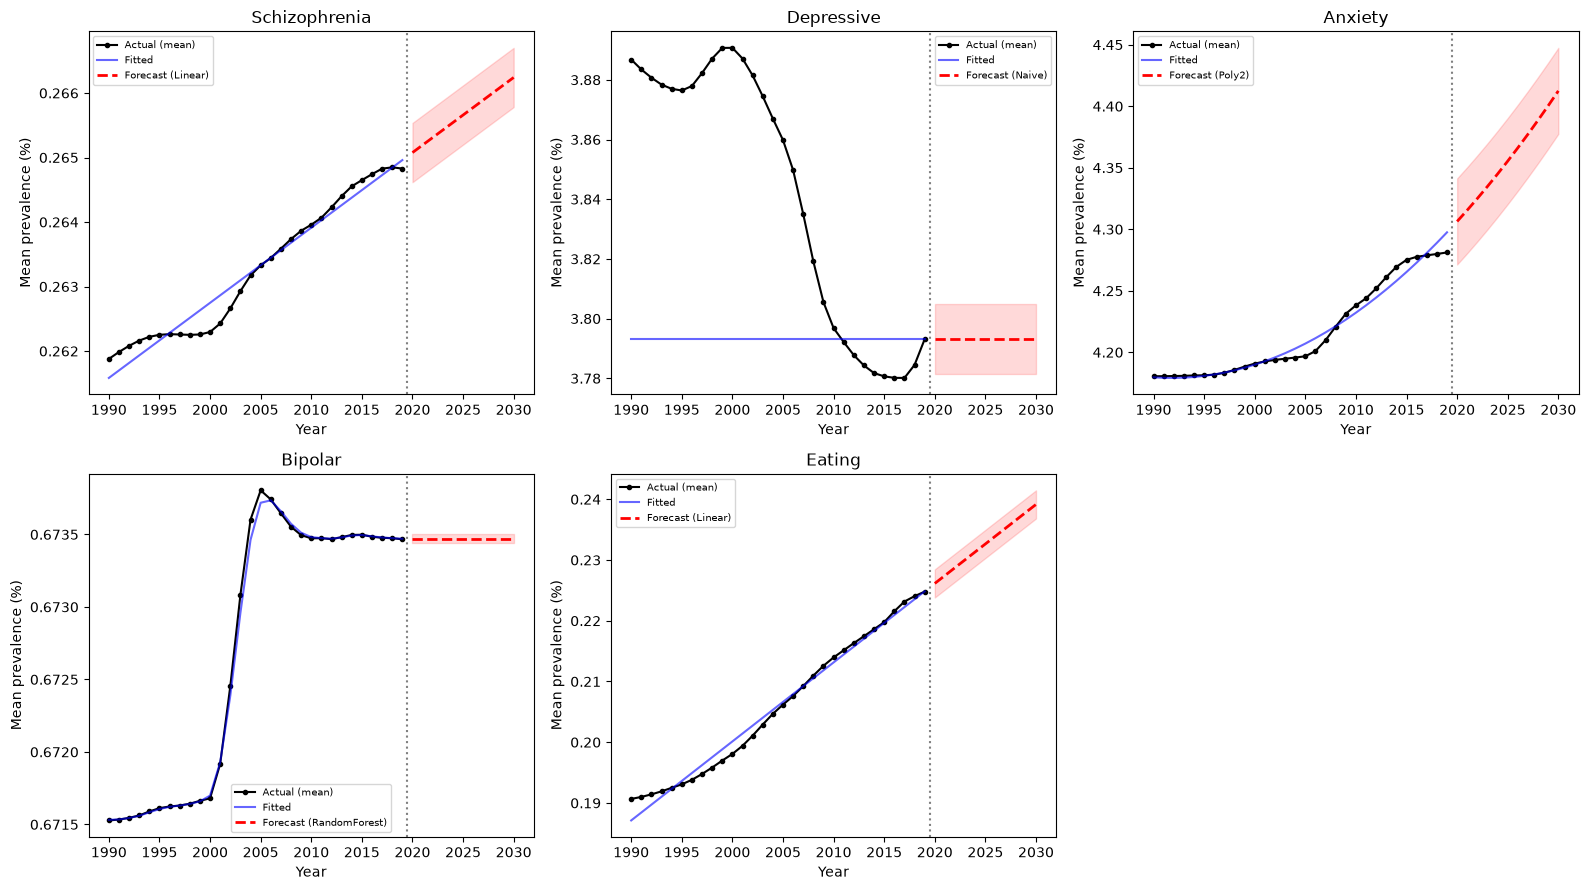


=== ค่าพยากรณ์ปี 2025 และ 2030 ===


,disease,model,year,forecast,lower,upper
5,Schizophrenia,Linear,2025,0.266,0.265,0.266
10,Schizophrenia,Linear,2030,0.266,0.266,0.267
16,Depressive,Naive,2025,3.793,3.781,3.805
21,Depressive,Naive,2030,3.793,3.781,3.805
27,Anxiety,Poly2,2025,4.355,4.320,4.390
32,Anxiety,Poly2,2030,4.412,4.378,4.447
38,Bipolar,RandomForest,2025,0.673,0.673,0.674
43,Bipolar,RandomForest,2030,0.673,0.673,0.674
49,Eating,Linear,2025,0.233,0.230,0.235
54,Eating,Linear,2030,0.239,0.237,0.241



บันทึกแล้ว


In [9]:
#คำถามที่ 3 สัดส่วนผู้ป่วยโรคทางจิตแต่ละประเภทแตกต่างกันอย่างไร แล้วจะมีแนวโน้มเป็นอย่างไรในอนาคต
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

BASE = r"C:\Users\LENOVO\OneDrive - BUU\Desktop\Data"
df = pd.read_csv(os.path.join(BASE, "processed", "mental_income_merged.csv"))
diseases = ["Schizophrenia", "Depressive", "Anxiety", "Bipolar", "Eating"]
order = ["Low income", "Lower-middle income", "Upper-middle income", "High income"]

tab_dir = os.path.join(BASE, "..", "Results", "tables")
fig_dir = os.path.join(BASE, "..", "Results", "figures")
os.makedirs(tab_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

# =====================================================
# ส่วนที่ 1: สัดส่วนของแต่ละโรค (% ของผลรวม 5 โรค)
# =====================================================
def to_share(means):
    return means.div(means.sum(axis=1), axis=0) * 100

# 1.1 รวมทุกประเทศ-ทุกปี
overall = df[diseases].mean()
share_overall = (overall / overall.sum() * 100).round(2).to_frame("share_%")
share_overall["mean_prevalence_%"] = overall.round(3)
print("=== สัดส่วนรวม (1990-2019) ===")
display(share_overall.sort_values("share_%", ascending=False))

# 1.2 แยกตามกลุ่มรายได้
share_income = to_share(df.groupby("income_group")[diseases].mean().loc[order]).round(2)
print("\n=== สัดส่วนแยกตามกลุ่มรายได้ (%) ===")
display(share_income)

# 1.3 เปรียบเทียบ 1990 กับ 2019
yearly_all = df.groupby("year")[diseases].mean()
share_year = to_share(yearly_all)
change = pd.DataFrame({
    "share_1990": share_year.loc[1990],
    "share_2019": share_year.loc[2019],
})
change["change_pp"] = change["share_2019"] - change["share_1990"]
print("\n=== สัดส่วนปี 1990 vs 2019 (จุดเปอร์เซ็นต์) ===")
display(change.round(3))

# 1.4 Anxiety กับ Depressive ต่างกันทางสถิติไหม (จับคู่ประเทศ-ปี)
w = stats.wilcoxon(df["Anxiety"], df["Depressive"])
print(f"\nWilcoxon Anxiety vs Depressive: p = {w.pvalue:.3g}")

share_overall.to_csv(os.path.join(tab_dir, "share_overall.csv"), encoding="utf-8-sig")
share_income.to_csv(os.path.join(tab_dir, "share_by_income.csv"), encoding="utf-8-sig")
change.to_csv(os.path.join(tab_dir, "share_change_1990_2019.csv"), encoding="utf-8-sig")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
share_income.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab20c")
axes[0].set_title("Share of each disorder by income group")
axes[0].set_ylabel("% of total (5 disorders)")
axes[0].set_xticklabels(["L", "LM", "UM", "H"], rotation=0)
share_year.plot(ax=axes[1], lw=2)
axes[1].set_title("Share of each disorder over time")
axes[1].set_ylabel("% of total (5 disorders)")
plt.tight_layout()
fig.savefig(os.path.join(fig_dir, "share_by_income_and_year.png"), dpi=300)
plt.show()

# =====================================================
# ส่วนที่ 2: พยากรณ์แนวโน้ม (ML)
# =====================================================
# ใช้เฉพาะประเทศที่มีข้อมูลครบ 30 ปี
n_years = df.groupby("country_code")["year"].nunique()
balanced = n_years[n_years == 30].index
d = df[df["country_code"].isin(balanced)]
print(f"\nประเทศที่ข้อมูลครบ 30 ปี: {len(balanced)} จาก {df['country_code'].nunique()}")

yearly = d.groupby("year")[diseases].mean()
years = yearly.index.values.astype(float)

try:
    from sklearn.ensemble import RandomForestRegressor
    HAS_SK = True
except Exception as e:
    HAS_SK = False
    print("ใช้ scikit-learn ไม่ได้ จะข้าม Random Forest:", str(e)[:80])

models = ["Naive", "Linear", "Poly2"] + (["RandomForest"] if HAS_SK else [])

def predict(model, xtr, ytr, xte):
    if model == "Naive":
        return np.full(len(xte), ytr[-1])
    if model == "Linear":
        return np.polyval(np.polyfit(xtr - 2000, ytr, 1), xte - 2000)
    if model == "Poly2":
        return np.polyval(np.polyfit(xtr - 2000, ytr, 2), xte - 2000)
    if model == "RandomForest":
        rf = RandomForestRegressor(n_estimators=300, random_state=42)
        rf.fit(xtr.reshape(-1, 1), ytr)
        return rf.predict(xte.reshape(-1, 1))

# 2.1 Backtest: train 1990-2012, test 2013-2019
train = years <= 2012
test = years >= 2013
bt = []
for dis in diseases:
    y = yearly[dis].values
    for m in models:
        pred = predict(m, years[train], y[train], years[test])
        rmse = np.sqrt(np.mean((y[test] - pred) ** 2))
        mape = np.mean(np.abs((y[test] - pred) / y[test])) * 100
        bt.append({"disease": dis, "model": m, "RMSE": rmse, "MAPE_%": mape})
bt = pd.DataFrame(bt)
best = bt.loc[bt.groupby("disease")["RMSE"].idxmin()].set_index("disease")
print("\n=== Backtest (test = 2013-2019) ===")
display(bt.pivot(index="disease", columns="model", values="RMSE").round(5))
print("โมเดลที่ดีที่สุดของแต่ละโรค:")
display(best[["model", "RMSE", "MAPE_%"]].round(4))
bt.to_csv(os.path.join(tab_dir, "forecast_backtest.csv"), index=False, encoding="utf-8-sig")

# 2.2 ฟิตใหม่ด้วยข้อมูลทั้งหมด แล้วพยากรณ์ 2020-2030
future = np.arange(2020, 2031).astype(float)
fc_rows = []
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, dis in zip(axes.ravel(), diseases):
    y = yearly[dis].values
    m = best.loc[dis, "model"]
    fit_in = predict(m, years, y, years)
    fc = predict(m, years, y, future)
    err = 1.96 * best.loc[dis, "RMSE"]            # ช่วงโดยประมาณจาก error ของ backtest
    for yr, v in zip(future, fc):
        fc_rows.append({"disease": dis, "model": m, "year": int(yr),
                        "forecast": v, "lower": v - err, "upper": v + err})
    ax.plot(years, y, "ko-", ms=3, label="Actual (mean)")
    ax.plot(years, fit_in, "b-", alpha=0.6, label="Fitted")
    ax.plot(future, fc, "r--", lw=2, label=f"Forecast ({m})")
    ax.fill_between(future, fc - err, fc + err, color="red", alpha=0.15)
    ax.axvline(2019.5, color="gray", ls=":")
    ax.set_title(dis)
    ax.set_xlabel("Year")
    ax.set_ylabel("Mean prevalence (%)")
    ax.legend(fontsize=7)
axes.ravel()[-1].axis("off")
plt.tight_layout()
fig.savefig(os.path.join(fig_dir, "forecast_2020_2030.png"), dpi=300)
plt.show()

fc_df = pd.DataFrame(fc_rows)
print("\n=== ค่าพยากรณ์ปี 2025 และ 2030 ===")
display(fc_df[fc_df["year"].isin([2025, 2030])].round(3))
fc_df.to_csv(os.path.join(tab_dir, "forecast_2020_2030.csv"), index=False, encoding="utf-8-sig")
print("\nบันทึกแล้ว")

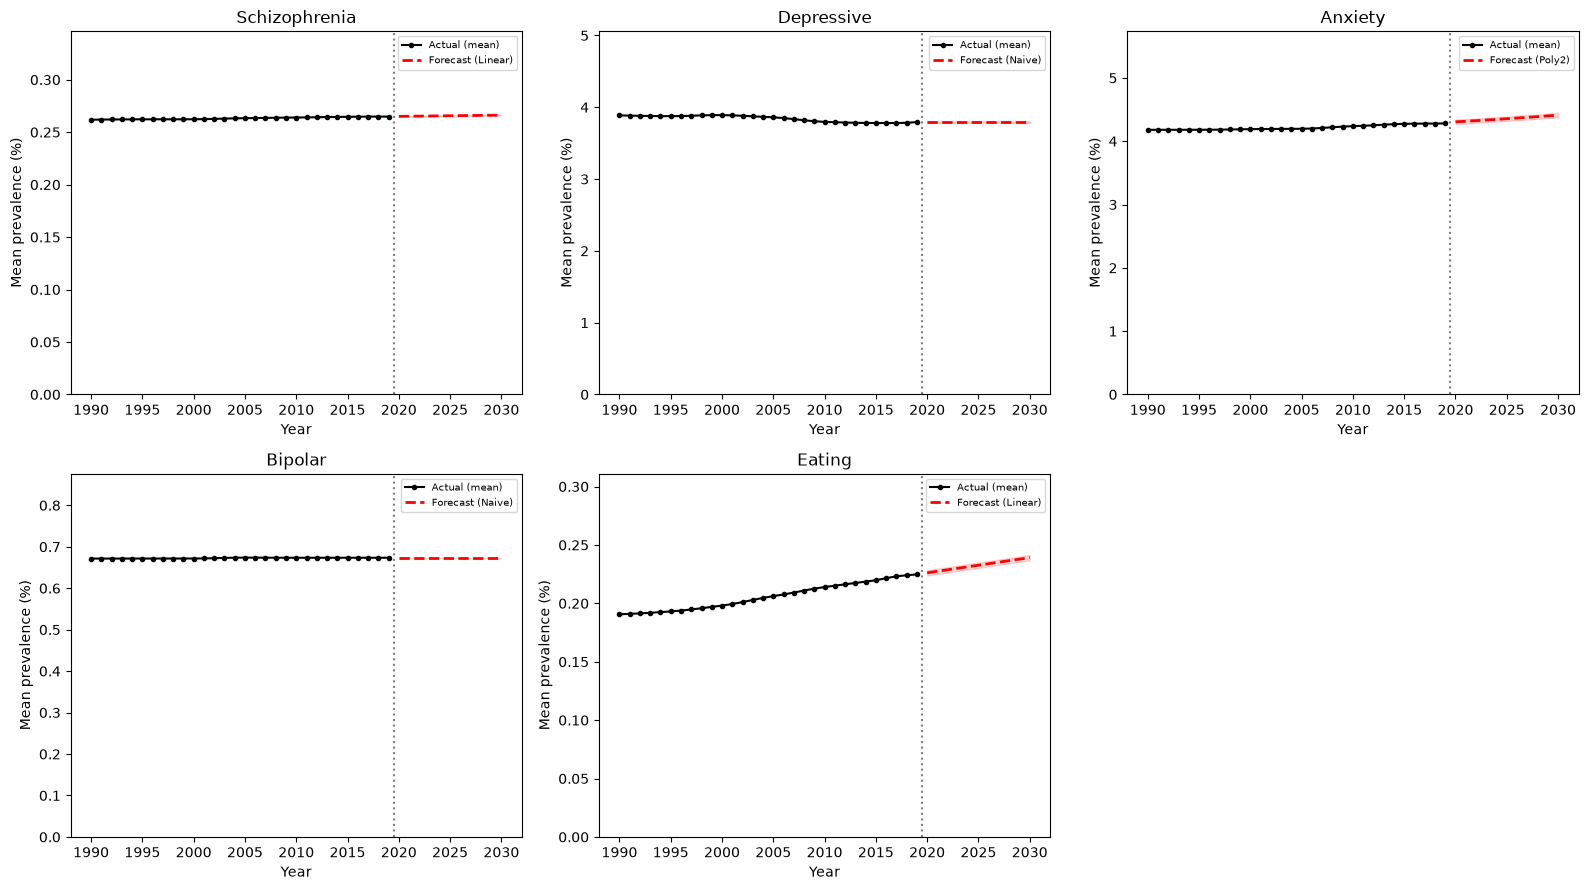

In [10]:
best.loc["Bipolar", "model"] = "Naive"

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, dis in zip(axes.ravel(), diseases):
    y = yearly[dis].values
    m = best.loc[dis, "model"]
    fc = predict(m, years, y, future)
    err = 1.96 * bt[(bt.disease == dis) & (bt.model == m)]["RMSE"].iloc[0]
    ax.plot(years, y, "ko-", ms=3, label="Actual (mean)")
    ax.plot(future, fc, "r--", lw=2, label=f"Forecast ({m})")
    ax.fill_between(future, fc - err, fc + err, color="red", alpha=0.15)
    ax.axvline(2019.5, color="gray", ls=":")
    ax.set_ylim(0, max(y.max(), fc.max()) * 1.3)
    ax.set_title(dis); ax.set_xlabel("Year"); ax.set_ylabel("Mean prevalence (%)")
    ax.legend(fontsize=7)
axes.ravel()[-1].axis("off")
plt.tight_layout()
fig.savefig(os.path.join(fig_dir, "forecast_2020_2030_ylim0.png"), dpi=300)
plt.show()

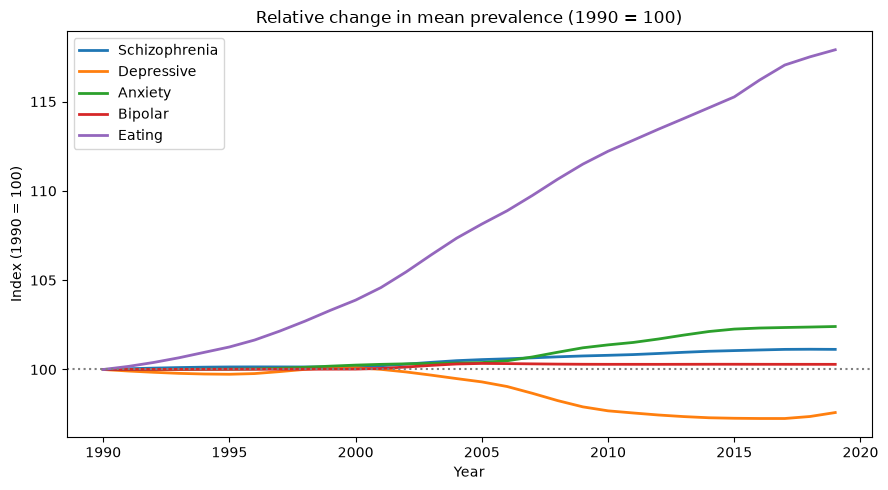

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
for dis in diseases:
    y = yearly[dis].values
    ax.plot(years, y / y[0] * 100, lw=2, label=dis)
ax.axhline(100, color="gray", ls=":")
ax.set_ylabel("Index (1990 = 100)")
ax.set_xlabel("Year")
ax.set_title("Relative change in mean prevalence (1990 = 100)")
ax.legend()
plt.tight_layout()
fig.savefig(os.path.join(fig_dir, "relative_change_index.png"), dpi=300)
plt.show()

In [ ]:
#เมื่อเทียบกับปี 1990 อัตราโรคการกินผิดปกติ (Eating) เพิ่มขึ้นสัมพัทธ์ราว 18% ซึ่งมากที่สุดในทุกโรค ขณะที่ Anxiety เพิ่มราว 2.5% และ Depressive ลดลงราว 2.5% ส่วน Bipolar และ Schizophrenia 
# แทบไม่เปลี่ยนแปลง อย่างไรก็ตามระดับอัตราที่แท้จริงของ Eating ยังต่ำ (ประมาณ 0.2%)
#  การเพิ่มเชิงสัมบูรณ์จึงเล็กน้อย

In [ ]:
#สัดส่วนผู้ป่วยโรคทางจิตถูกครอบงำโดย Anxiety (45.6%) และ Depressive (42.0%) รวมกันราว 88% ส่วน Bipolar, Schizophrenia และ Eating มีสัดส่วนน้อย (7.2%, 3.0%, 2.2%) 
# สัดส่วนต่างกันตามระดับรายได้ (Depressive สูงในกลุ่มรายได้ต่ำ ส่วน Anxiety และ Eating สูงในกลุ่มรายได้สูง) การพยากรณ์ถึงปี 2030 ชี้ว่าอัตราโรคโดยเฉลี่ยค่อนข้างคงที่
#  โดย Anxiety และ Eating มีแนวโน้มเพิ่มขึ้นเล็กน้อย